# Этап 2. Фоновые машины и тормозящий нарушитель

Код: `rssrl/violators.py`, проверки: `tests/test_violators.py`.

1. Фоновые машины highway-env тормозят до 6 м/с², хотя RSS допускает только 5 м/с². Показываем это и исправляем.
2. Нарушитель в момент нарушения сам задает себе цель −β·5 м/с² в обход IDM и набирает торможение с пределом рывка J_max = 10 м/с³ (`rssrl/dynamics.py`). Проверяем, что фактическое торможение выходит ровно на заданное и набирается не быстрее J_max.

Предел рывка действует на все машины (агент, фильтр, нарушитель, фон): ускорение за шаг 1/15 с меняется не больше чем на 10/15 ≈ 0,67 м/с². Значение 10 м/с³ — порядок рывка обычного водителя при экстренном торможении (≈ 11 м/с³; у базовой системы AEB ≈ 20 м/с³; Applus IDIADA, The BRAKE Report, 2019). Комфортный рывок (≈ 2–3 м/с³, Hoberock, 1976) жестким пределом не берем: в экстренных ситуациях его превышают.

In [1]:
import sys
sys.path.insert(0, '..')
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rssrl.scenarios import make_env, find_leader
from rssrl.violators import BrakingViolator
from rssrl.dynamics import J_MAX

FIG = Path('..') / 'results' / 'figures'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.3, 'lines.linewidth': 2})
DT = 1 / 15
BETAS = [1.0, 1.2, 1.4, 1.6, 1.8, 2.0]

## 1. Торможение фоновых машин: стандартный IDM и наш BoundedIDMVehicle

10 сцен по 40 с, у каждой машины на каждом шаге считаем фактическое ускорение по изменению скорости.

In [2]:
def background_accels(vehicle_type, seeds=range(10), seconds=40):
    out = []
    for s in seeds:
        env = make_env(s, other_vehicles_type=vehicle_type)
        road, ego = env.unwrapped.road, env.unwrapped.vehicle
        for _ in range(seconds * 15):
            before = {id(v): v.speed for v in road.vehicles}
            road.act(); road.step(DT)
            out += [(v.speed - before[id(v)]) / DT for v in road.vehicles
                    if v is not ego and not v.crashed]
        env.close()
    return np.array(out)

stock = background_accels('highway_env.vehicle.behavior.IDMVehicle')
bounded = background_accels('rssrl.violators.BoundedIDMVehicle')
summary = pd.DataFrame({
    'машина': ['IDMVehicle (как в highway-env)', 'BoundedIDMVehicle (наша)'],
    'шагов всего': [stock.size, bounded.size],
    'шагов с торможением > 5 м/с²': [(stock < -5 - 1e-9).sum(), (bounded < -5 - 1e-9).sum()],
    'самое сильное торможение, м/с²': [-stock.min(), -bounded.min()],
})
summary

,машина,шагов всего,шагов с торможением > 5 м/с²,"самое сильное торможение, м/с²"
0,IDMVehicle (как в highway-env),297438,1271,6.0
1,BoundedIDMVehicle (наша),297181,0,5.0


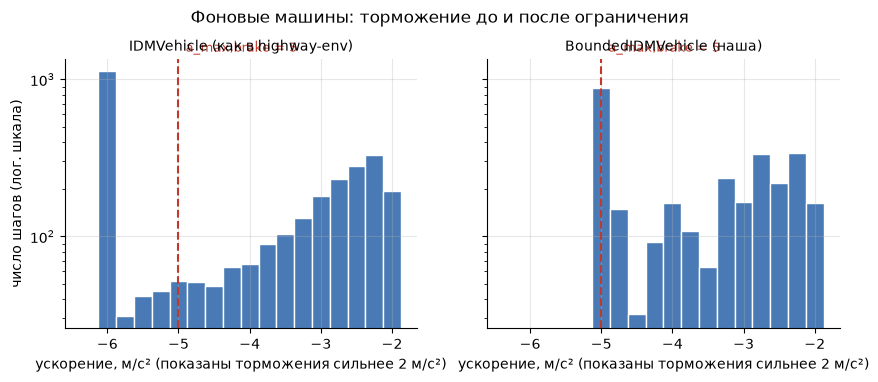

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
bins = np.arange(-6.375, -1.874, 0.25)  # столбцы центрированы на -6, -5.75, ..., -2
for ax, data, name in zip(axes, [stock, bounded], ['IDMVehicle (как в highway-env)', 'BoundedIDMVehicle (наша)']):
    hard = data[data < -2]  # интересны только сильные торможения
    ax.hist(hard, bins=bins, color='#4a7ab5', edgecolor='white', linewidth=1)
    ax.axvline(-5, color='#c0392b', linewidth=1.5, linestyle='--')
    ax.text(-4.9, 1.5e3, 'a_max,brake = 5', color='#c0392b', fontsize=9)
    ax.set_title(name, fontsize=10)
    ax.set_xlabel('ускорение, м/с² (показаны торможения сильнее 2 м/с²)')
    ax.set_yscale('log')
axes[0].set_ylabel('число шагов (лог. шкала)')
fig.suptitle('Фоновые машины: торможение до и после ограничения', y=1.02)
fig.savefig(FIG / '02_background_braking.png', dpi=150, bbox_inches='tight')
plt.show()

Стандартные IDM-машины иногда тормозят сильнее 5 м/с², максимум до 6 м/с². Это нарушает допущение RSS ещё до появления нарушителя, и смешивалось бы с эффектом β. После ограничения таких шагов нет. У нашей машины еще и предел рывка, поэтому сильные торможения набираются постепенно.

Не стали ли фоновые машины из-за этого сталкиваться между собой? Проверяем на 30 сценах по 40 с (агент «бесплотный», чтобы считать только фоновые машины):

In [4]:
def background_crashes(vehicle_type, seeds=range(30), seconds=40):
    crashed = 0
    for s in seeds:
        env = make_env(s, other_vehicles_type=vehicle_type)
        road, ego = env.unwrapped.road, env.unwrapped.vehicle
        ego.collidable = False
        for _ in range(seconds * 15):
            road.act(); road.step(DT)
        crashed += sum(v.crashed for v in road.vehicles if v is not ego)
        env.close()
    return crashed

for name, typ in [('IDMVehicle', 'highway_env.vehicle.behavior.IDMVehicle'),
                  ('BoundedIDMVehicle', 'rssrl.violators.BoundedIDMVehicle')]:
    print(f'{name:18s} столкнувшихся фоновых машин за 30 сцен: {background_crashes(typ)}')

IDMVehicle         столкнувшихся фоновых машин за 30 сцен: 0


BoundedIDMVehicle  столкнувшихся фоновых машин за 30 сцен: 0


## 2. Нарушитель: задано / фактически

Лидера агента заменяем нарушителем, нарушение начинается через 1 с. Чтобы столкновение с агентом не оборвало торможение, агента на время этой проверки делаем «бесплотным» (`collidable = False`). Здесь проверяется только сам нарушитель. Для каждого β берем 10 сцен (seed 0–9).

In [5]:
rows, traces = [], {}
for beta in BETAS:
    for seed in range(10):
        env = make_env(seed)
        env.unwrapped.vehicle.collidable = False
        vio = BrakingViolator.replace(find_leader(env), beta=beta, trigger_time=1.0)
        for _ in range(8):
            env.step(1)
        env.close()
        e = vio.events[0]
        a = np.array(e['a_actual'])
        if seed == 0:
            traces[beta] = e
        a0 = e['a_set'][0] + J_MAX * DT  # ускорение до начала нарушения
        k = int(np.argmax(np.isclose(a, e['a_commanded'], atol=1e-9)))  # первый шаг на полке
        rows.append({'β': beta, 'seed': seed, 'задано, м/с²': e['a_commanded'],
                     'фактически на полке': a[k:-1].mean(),
                     'макс. отклонение на полке': np.abs(a[k:-1] - e['a_commanded']).max(),
                     'макс. рывок, м/с³': np.abs(np.diff(np.r_[a0, a[:-1]])).max() / DT,
                     'набор, с': (k + 1) * DT,
                     '(β·5 + a0)/J_max, с': (5 * beta + a0) / J_MAX,
                     'последний шаг': a[-1], 'v в начале, м/с': e['v_start'],
                     'время торможения, с': e['t_stop'] - e['t_start'],
                     'v/(β·5), с': e['v_start'] / (5 * beta)})
events = pd.DataFrame(rows)
events.groupby('β')[['задано, м/с²', 'фактически на полке', 'макс. отклонение на полке',
                     'макс. рывок, м/с³', 'набор, с', '(β·5 + a0)/J_max, с']].mean().round(4)

,"задано, м/с²",фактически на полке,макс. отклонение на полке,"макс. рывок, м/с³","набор, с","(β·5 + a0)/J_max, с"
β,,,,,,
1.0,-5.0,-5.0,0.0,10.0,0.4600,0.4191
1.2,-6.0,-6.0,0.0,10.0,0.5467,0.5191
1.4,-7.0,-7.0,0.0,10.0,0.6600,0.6191
1.6,-8.0,-8.0,0.0,10.0,0.7467,0.7191
1.8,-9.0,-9.0,0.0,10.0,0.8600,0.8191
2.0,-10.0,-10.0,0.0,10.0,0.9467,0.9191


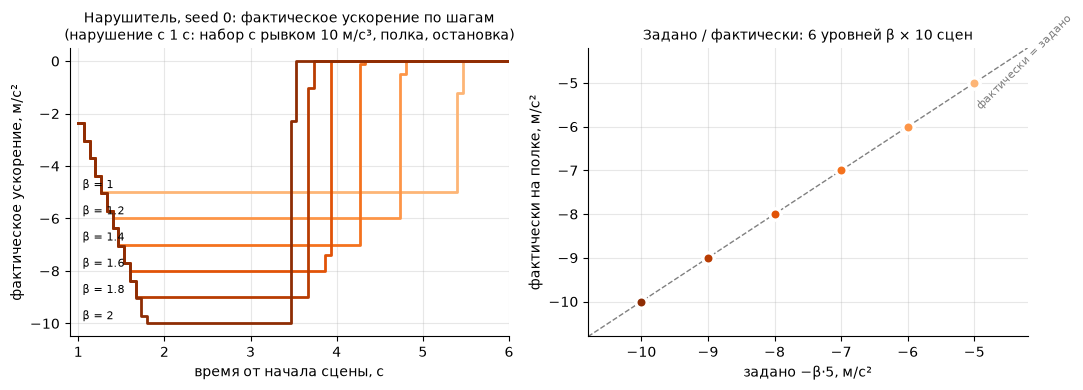

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
colors = plt.cm.Oranges(np.linspace(0.35, 0.95, len(BETAS)))

ax = axes[0]
for beta, c in zip(BETAS, colors):
    e = traces[beta]
    # фаза торможения: от начала нарушения до остановки, дальше 0
    t = np.r_[e['t'], e['t'][-1] + DT, 6.0]
    a = np.r_[e['a_actual'], 0.0, 0.0]
    ax.step(t, a, where='post', color=c)
    ax.annotate(f'β = {beta:g}', (1.05, e['a_commanded']),
                xytext=(0, 3), textcoords='offset points', fontsize=8)
ax.set_xlabel('время от начала сцены, с'); ax.set_ylabel('фактическое ускорение, м/с²')
ax.set_title('Нарушитель, seed 0: фактическое ускорение по шагам\n'
             '(нарушение с 1 с: набор с рывком 10 м/с³, полка, остановка)', fontsize=10)
ax.set_xlim(0.9, 6.0)

ax = axes[1]
lim = [-10.8, -4.2]
ax.plot(lim, lim, color='gray', linewidth=1, linestyle='--')
ax.text(-5.0, -5.6, 'фактически = задано', color='gray', fontsize=8, rotation=45)
for beta, c in zip(BETAS, colors):
    sub = events[events['β'] == beta]
    ax.scatter(sub['задано, м/с²'], sub['фактически на полке'],
               color=c, s=60, edgecolor='white', linewidth=2, zorder=3)
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel('задано −β·5, м/с²'); ax.set_ylabel('фактически на полке, м/с²')
ax.set_title('Задано / фактически: 6 уровней β × 10 сцен', fontsize=10)
fig.tight_layout()
fig.savefig(FIG / '02_violator_commanded_vs_actual.png', dpi=150, bbox_inches='tight')
plt.show()

Торможение набирается ровно с рывком J_max = 10 м/с³: время набора совпадает с (β·5 + a0)/J_max с точностью до шага (a0 — ускорение лидера до нарушения). После набора фактическое ускорение совпадает с заданным −β·5 на всех шагах, кроме последнего: там машина дотормаживает до нуля, чтобы не уехать назад. Из-за набора время торможения чуть больше v/(β·5) — примерно на половину времени набора. Фактическое ускорение каждого события по-прежнему пишется в лог.

In [7]:
events[['β', 'seed', 'v в начале, м/с', 'набор, с', 'время торможения, с', 'v/(β·5), с', 'последний шаг']].head(12).round(3)

,β,seed,"v в начале, м/с","набор, с","время торможения, с","v/(β·5), с",последний шаг
0,1.0,0,21.647,0.333,4.467,4.329,-1.228
1,1.0,1,19.133,0.400,3.933,3.827,-4.366
2,1.0,2,21.453,0.533,4.533,4.291,-2.444
3,1.0,3,20.697,0.533,4.333,4.139,-4.855
4,1.0,4,19.543,0.333,4.000,3.909,-4.014
5,1.0,5,21.968,0.467,4.533,4.394,-4.641
6,1.0,6,22.230,0.533,4.667,4.446,-3.266
7,1.0,7,21.518,0.467,4.467,4.304,-3.748
8,1.0,8,21.670,0.533,4.600,4.334,-0.387
9,1.0,9,23.256,0.467,4.867,4.651,-2.182
